<a href="https://colab.research.google.com/github/dwyu0/UTS_ACC_2501010134/blob/main/UTS_ACC_2501010134.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MEMBUAT FOLDER

In [ ]:
import os
import shutil

# 1. Daftar folder yang perlu dibuat untuk proyek UTS
folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "reports/figures"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)
    print(f"Folder dibuat/dipastikan ada: {folder}")

# 2. Pindahkan file dataset mentah utama ke folder data/raw/
file_sumber = "indonesia_pariwisata_super_prioritas_enriched.csv"
file_tujuan = os.path.join("data/raw", file_sumber)

if os.path.exists(file_sumber):
    shutil.copy(file_sumber, file_tujuan)
    print(f"File '{file_sumber}' berhasil disalin ke '{file_tujuan}'")
else:
    print(f"Perhatian: File '{file_sumber}' tidak ditemukan di direktori saat ini.")

MENGHUBUNGKAN GOOGLE COLAB KE DRIVE

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import shutil
import pandas as pd

# 1. Pastikan folder data/raw di dalam project kamu sudah ada
os.makedirs("data/raw", exist_ok=True)

# 2. Tentukan jalur file di Google Drive kamu
# Sesuaikan jika folder di Drive kamu berbeda namanya (contoh: di folder My Drive)
file_sumber_drive = "/content/drive/My Drive/indonesia_pariwisata_super_prioritas_enriched.csv"
file_tujuan = "data/raw/indonesia_pariwisata_super_prioritas_enriched.csv"

# 3. Salin dari Google Drive ke folder lokal data/raw/ di Colab
if os.path.exists(file_sumber_drive):
    shutil.copy(file_sumber_drive, file_tujuan)

    # Verifikasi dengan Pandas untuk memastikan file terbaca dengan benar
    df = pd.read_csv(file_tujuan)
    print(f"Sukses! File berhasil disalin ke: {file_tujuan}")
    print(f"Total Baris Dataset: {df.shape[0]} (Memenuhi syarat >= 100 baris)")
    print(f"Total Kolom: {df.shape[1]}")
else:
    print(f"File tidak ditemukan di Google Drive pada path: {file_sumber_drive}")
    print("Tips: Cek kembali apakah file sudah di-upload ke folder root Google Drive kamu.")

Sukses! File berhasil disalin ke: data/raw/indonesia_pariwisata_super_prioritas_enriched.csv
Total Baris Dataset: 10000 (Memenuhi syarat >= 100 baris)
Total Kolom: 26


Memfilter dataset utama agar hanya mengambil data yang khusus wilayah Bali (Bali Greater Hub), lalu melakukan pengecekan awal untuk memastikan data tersebut valid dan siap diolah.

In [4]:
from IPython.display import display, Markdown

# Filter dataset utama (df) untuk wilayah Bali (destination_cluster == 'Bali Greater Hub')
df_bali = df[df['destination_cluster'] == 'Bali Greater Hub'].copy()

# Menampilkan menggunakan markdown render di Jupyter/Colab
display(Markdown("### === PREVIEW TABEL BERSIH (5 Baris Pertama) ==="))
display(df_bali.head(5))

### === PREVIEW TABEL BERSIH (5 Baris Pertama) ===

,tourist_trip_id,observation_date,destination_cluster,is_super_priority_destination,tourist_origin_category,travel_party_size,trip_duration_days,accommodation_type,hotel_room_rate_per_night_idr,hotel_occupancy_rate_pct,...,daily_spending_per_person_idr,spending_to_room_rate_ratio,destination_carrying_capacity_index,tourism_economic_multiplier_score,accessibility_friction_score,tourist_spending_tier,destination_competitiveness_index,primary_travel_friction_factor,cot_tourism_economy_rationale,confidence_score
0,TOUR_IDN_2026_01618,2026-01-03,Bali Greater Hub,False,Wisatawan Nusantara Domestik Antar-Provinsi,2,5,Hotel Bintang 1-3,600000,62.3,...,1530000.0,2.55,5.97,7.37,2.0,Tier 2 - Mid-Scale Comfort,8.16,Zero-Friction-Optimal,Perjalanan 'TOUR_IDN_2026_01618' pada '2026-01...,0.965
1,TOUR_IDN_2026_01798,2026-01-03,Bali Greater Hub,False,Wisatawan Nusantara Domestik Antar-Provinsi,4,5,Villa / Glamping Ekologis,1810000,69.1,...,2670000.0,1.48,6.44,8.24,1.5,Tier 3 - Premium Experience,8.16,Zero-Friction-Optimal,Perjalanan 'TOUR_IDN_2026_01798' pada '2026-01...,0.976
2,TOUR_IDN_2026_02991,2026-01-03,Bali Greater Hub,False,Wisatawan Mancanegara Non-ASEAN,2,12,Hotel Bintang 4-5 Resort,4270000,85.0,...,2916667.0,0.68,6.99,7.50,3.3,Tier 4 - Ultra-Luxury VIP,8.36,Zero-Friction-Optimal,Perjalanan 'TOUR_IDN_2026_02991' pada '2026-01...,0.990
3,TOUR_IDN_2026_03138,2026-01-03,Bali Greater Hub,False,Wisatawan Domestik Lokal Intra-Provinsi,3,3,Hotel Bintang 1-3,940000,68.4,...,1540000.0,1.64,6.33,6.87,1.3,Tier 2 - Mid-Scale Comfort,7.78,Zero-Friction-Optimal,Perjalanan 'TOUR_IDN_2026_03138' pada '2026-01...,0.978
4,TOUR_IDN_2026_09728,2026-01-03,Bali Greater Hub,False,Wisatawan Mancanegara Non-ASEAN,2,9,Homestay Desa Wisata Lokal,400000,66.9,...,2861111.0,7.15,6.18,8.19,1.5,Tier 4 - Ultra-Luxury VIP,8.78,Zero-Friction-Optimal,Perjalanan 'TOUR_IDN_2026_09728' pada '2026-01...,0.982


Mengapus data yang berulang

In [5]:
import pandas as pd
from pathlib import Path

Path("data/processed").mkdir(parents=True, exist_ok=True)
print(f"Jumlah baris awal: {df_bali.shape[0]}")

# 1. Hapus duplikat
df_clean = df_bali.drop_duplicates().copy()

# 2. Rapikan spasi di SEMUA kolom teks sekaligus
obj_cols = df_clean.select_dtypes(include='object').columns
df_clean[obj_cols] = df_clean[obj_cols].apply(lambda s: s.str.strip())

# 3. Isi missing value kolom teks (tanpa loop for)
text_cols = [
    'destination_cluster', 'tourist_origin_category', 'accommodation_type',
    'primary_transport_mode', 'primary_travel_motive', 'primary_travel_friction_factor'
]
valid_text = df_clean.columns.intersection(text_cols)
df_clean[valid_text] = df_clean[valid_text].fillna('Tidak Diketahui')

# 4. Format tanggal
if 'observation_date' in df_clean.columns:
    df_clean['observation_date'] = pd.to_datetime(df_clean['observation_date'], errors='coerce')

# 5. Konversi SEMUA kolom angka sekaligus (tanpa loop for)
numeric_cols = [
    'travel_party_size', 'trip_duration_days', 'hotel_room_rate_per_night_idr',
    'hotel_occupancy_rate_pct', 'total_spending_per_person_idr', 'daily_spending_per_person_idr',
    'flight_accessibility_index', 'eco_tourism_satisfaction_score', 'destination_carrying_capacity_index',
    'tourism_economic_multiplier_score', 'accessibility_friction_score', 'destination_competitiveness_index'
]
valid_num = df_clean.columns.intersection(numeric_cols)
df_clean[valid_num] = df_clean[valid_num].apply(pd.to_numeric, errors='coerce')

print(f"Jumlah baris setelah dibersihkan: {df_clean.shape[0]}")

# 6. Preview & Simpan
display_cols = ['tourist_trip_id', 'observation_date', 'tourist_origin_category', 'trip_duration_days', 'total_spending_per_person_idr']
display(df_clean[df_clean.columns.intersection(display_cols)].head())

output_path = "data/processed/df_bali_final_clean.csv"
df_clean.to_csv(output_path, index=False)
print(f"Data bersih disimpan ke '{output_path}'")

Jumlah baris awal: 2051
Jumlah baris setelah dibersihkan: 2051


,tourist_trip_id,observation_date,tourist_origin_category,trip_duration_days,total_spending_per_person_idr
0,TOUR_IDN_2026_01618,2026-01-03,Wisatawan Nusantara Domestik Antar-Provinsi,5,7650000
1,TOUR_IDN_2026_01798,2026-01-03,Wisatawan Nusantara Domestik Antar-Provinsi,5,13350000
2,TOUR_IDN_2026_02991,2026-01-03,Wisatawan Mancanegara Non-ASEAN,12,35000000
3,TOUR_IDN_2026_03138,2026-01-03,Wisatawan Domestik Lokal Intra-Provinsi,3,4620000
4,TOUR_IDN_2026_09728,2026-01-03,Wisatawan Mancanegara Non-ASEAN,9,25750000


Data bersih disimpan ke 'data/processed/df_bali_final_clean.csv'


In [9]:
import os
import hashlib
import requests
import pandas as pd
from io import StringIO
from datetime import datetime
from urllib.robotparser import RobotFileParser

# 1. Pastikan folder data/raw tersedia
os.makedirs("data/raw", exist_ok=True)

# 2. Fungsi helper untuk menghitung MD5 Hash (agar tidak NameError)
def calculate_md5(file_path):
    hash_md5 = hashlib.md5()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(4096), b""):
            hash_md5.update(chunk)
    return hash_md5.hexdigest()

# 3. Inisialisasi list provenance_records jika belum ada
if 'provenance_records' not in locals():
    provenance_records = []

# ==========================================
# 2. WEB SCRAPING WIKIPEDIA (Etis & Kepatuhan Robots.txt)
# ==========================================
print("Sedang melakukan Web Scraping ke Wikipedia (Pariwisata di Bali)...")

# Target artikel Wikipedia pariwisata Bali
target_url = "https://id.wikipedia.org/wiki/Pariwisata_di_Bali"
robots_url = "https://id.wikipedia.org/robots.txt"

# Wikimedia mewajibkan format User-Agent yang jelas (nama bot/tugas + kontak)
user_agent_name = "AkademikBot-BIFP243/1.0 (contact: mahasiswa@kampus.ac.id)"
headers = {'User-Agent': user_agent_name}

# 1. Audit robots.txt secara etis (Gunakan requests agar tidak diblokir 403)
rp = RobotFileParser()
try:
    resp_robots = requests.get(robots_url, headers=headers, timeout=10)
    rp.parse(resp_robots.text.splitlines())
    is_allowed = rp.can_fetch(user_agent_name, target_url)
except Exception as e:
    print(f"Gagal memeriksa robots.txt: {e}")
    is_allowed = False

print(f"-> Bukti Pemeriksaan robots.txt: is_allowed = {is_allowed}")

if is_allowed:
    # 2. Ambil HTML Halaman
    wiki_response = requests.get(target_url, headers=headers, timeout=10)

    if wiki_response.status_code == 200:
        file_c_path = "data/raw/wikipedia_pariwisata_bali.html"

        # Simpan file HTML mentah
        with open(file_c_path, "w", encoding="utf-8") as f:
            f.write(wiki_response.text)

        # 3. Ekstrak tabel dengan pandas
        try:
            tables = pd.read_html(StringIO(wiki_response.text))
            if tables:
                df_wiki_table = tables[0]  # Ambil tabel pertama yang ditemukan
                df_wiki_table.to_csv("data/raw/tabel_wikipedia_bali.csv", index=False)
                print(f"-> Sukses mengekstrak tabel Wikipedia ({df_wiki_table.shape[0]} baris) ke 'data/raw/tabel_wikipedia_bali.csv'")
                display(df_wiki_table.head())
        except Exception as err:
            print(f"Catatan ekstraksi tabel: {err}")

        # 4. Catat Data Provenance (MD5 Hash)
        md5_c = calculate_md5(file_c_path)
        provenance_records.append({
            "sumber": "Wikipedia Bahasa Indonesia (Pariwisata di Bali)",
            "file_lokal": file_c_path,
            "url": target_url,
            "tanggal_akses": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "lisensi": "Creative Commons Attribution-ShareAlike 4.0 (CC BY-SA 4.0)",
            "md5_hash": md5_c
        })
        print("-> Sukses menyimpan HTML mentah Wikipedia dan mencatat provenance!")
else:
    print("-> Akses web scraping dibatasi oleh robots.txt.")

Sedang melakukan Web Scraping ke Wikipedia (Pariwisata di Bali)...
-> Bukti Pemeriksaan robots.txt: is_allowed = True
-> Sukses mengekstrak tabel Wikipedia (6 baris) ke 'data/raw/tabel_wikipedia_bali.csv'


,Tahun,Jumlah Kunjungan,Perbandingan (%)
0,2010,2493058,tidak ada data
1,2011,2756579,+10.57%
2,2012,2892019,+4.91%
3,2013,3278598,+13.37%
4,2014,3766638,+14.89%


-> Sukses menyimpan HTML mentah Wikipedia dan mencatat provenance!


=== 1. MEMUAT DATASET PARIWISATA BALI ===
-> Tanggal sinkronisasi data cuaca: 2026-01-03 s/d 2026-03-04

=== 2. MENGAMBIL DATA API CUACA (OPEN-METEO) ===
-> Sukses normalisasi data API cuaca (61 baris). Preview:


,tanggal,suhu_maks,curah_hujan
0,2026-01-03,27.5,9.3
1,2026-01-04,26.1,2.2
2,2026-01-05,25.4,6.1



=== 3. AUDIT ROBOTS.TXT & WEB SCRAPING WIKIPEDIA ===
-> Bukti Pemeriksaan Kepatuhan robots.txt: is_allowed = True
-> Sukses mengekstrak tabel Wikipedia (6 baris). Preview:


,Tahun,Jumlah Kunjungan,Perbandingan (%)
0,2010,2493058,tidak ada data
1,2011,2756579,+10.57%
2,2012,2892019,+4.91%
3,2013,3278598,+13.37%
4,2014,3766638,+14.89%
5,2015,4001835,+6.24%


-> Berkas provenance_metadata.json lengkap tersimpan!

=== 4. PENGGABUNGAN DATA (SOAL 5) ===
-> Bukti Pemeriksaan Duplikasi: 0 baris duplikat.
-> Sukses! Berkas tersimpan di 'data/processed/df_bali_cuaca_merged.csv' (61 baris)

=== TABEL HASIL PENGGABUNGAN DATA (PREVIEW) ===


,observation_date,jumlah_kunjungan,tanggal,suhu_maks,curah_hujan
0,2026-01-03,5,2026-01-03,27.5,9.3
1,2026-01-04,6,2026-01-04,26.1,2.2
2,2026-01-05,2,2026-01-05,25.4,6.1
3,2026-01-06,8,2026-01-06,25.8,5.8
4,2026-01-07,9,2026-01-07,26.8,4.5
5,2026-01-08,6,2026-01-08,26.3,9.2
6,2026-01-09,5,2026-01-09,26.2,11.1
7,2026-01-10,8,2026-01-10,27.2,8.6
8,2026-01-11,8,2026-01-11,24.5,49.2
9,2026-01-12,6,2026-01-12,27.0,4.7


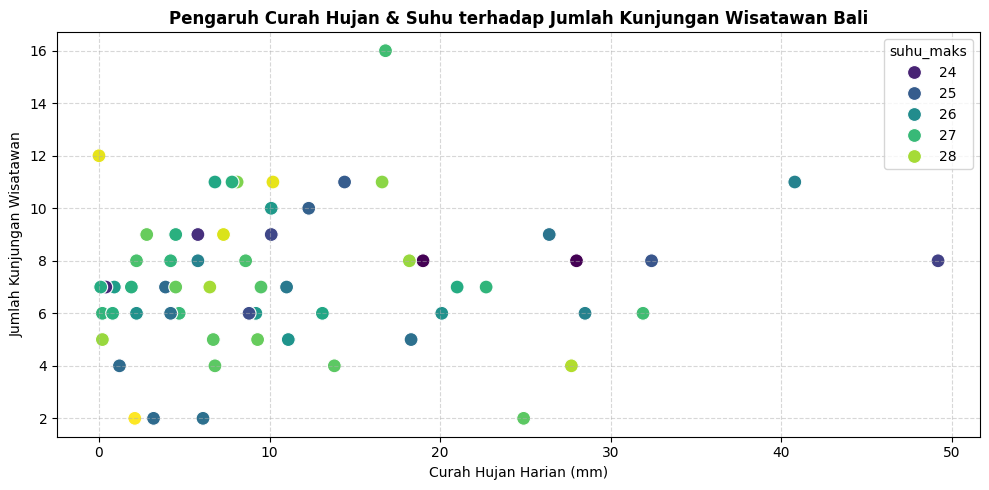

-> Diagram berhasil digenerate dan disimpan ke 'data/processed/diagram_cuaca_vs_kunjungan.png'


In [20]:
import os
import json
import time
import hashlib
import requests
import pandas as pd
from io import StringIO
from datetime import datetime
from urllib.robotparser import RobotFileParser
from requests.adapters import HTTPAdapter
from urllib3.util import Retry
import matplotlib.pyplot as plt
import seaborn as sns

# Pastikan struktur folder dasar
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

def calculate_md5(file_path):
    hash_md5 = hashlib.md5()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(4096), b""):
            hash_md5.update(chunk)
    return hash_md5.hexdigest()

# Setup Session HTTP (Timeout, Retry Otomatis, dan Identitas Kampus INSTIKI)
session = requests.Session()
retries = Retry(total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])
session.mount('https://', HTTPAdapter(max_retries=retries))

CAMPUS_EMAIL = "mahasiswa@instiki.ac.id"  # Silakan sesuaikan jika perlu
COMMON_HEADERS = {'User-Agent': f"AkademikBot-INSTIKI/1.0 (contact: {CAMPUS_EMAIL})"}
provenance_records = []

# ==============================================================
# TAHAP 1: BACA BERKAS LOKAL & CEK RENTANG TANGGAL ASLI (Soal 1)
# ==============================================================
print("=== 1. MEMUAT DATASET PARIWISATA BALI ===")
file_a_path = "data/raw/indonesia_pariwisata_super_prioritas_enriched.csv"
df_raw = pd.read_csv(
    file_a_path,
    sep=',',
    encoding='utf-8',
    na_values=['NA', 'null', 'None', '']
)
df_bali = df_raw[df_raw['destination_cluster'] == 'Bali Greater Hub'].copy()

# Pastikan kolom tanggal seragam dan hilangkan komponen jam
date_col = 'observation_date' if 'observation_date' in df_bali.columns else 'tanggal'
df_bali[date_col] = pd.to_datetime(df_bali[date_col]).dt.normalize()

# Catat Provenance Sumber 1
provenance_records.append({
    "sumber": "Dataset Terbuka Pariwisata Super Prioritas (Kaggle/Satu Data)",
    "file_lokal": file_a_path,
    "url": "https://www.kaggle.com/",
    "tanggal_akses": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "lisensi": "Open Data Commons / CC BY 4.0",
    "md5_hash": calculate_md5(file_a_path)
})

# Dapatkan tanggal awal dari dataset agar API cuaca sinkron (minimal 45 hari)
start_dt = df_bali[date_col].min()
end_dt = start_dt + pd.Timedelta(days=60)
start_date_str = start_dt.strftime('%Y-%m-%d')
end_date_str = end_dt.strftime('%Y-%m-%d')
print(f"-> Tanggal sinkronisasi data cuaca: {start_date_str} s/d {end_date_str}")

# ==============================================================
# TAHAP 2: AKUISISI DATA CUACA VIA API OPEN-METEO (Soal 3)
# ==============================================================
print("\n=== 2. MENGAMBIL DATA API CUACA (OPEN-METEO) ===")
url_api = f"https://archive-api.open-meteo.com/v1/archive?latitude=-8.4095&longitude=115.1889&start_date={start_date_str}&end_date={end_date_str}&daily=temperature_2m_max,precipitation_sum"

try:
    response = session.get(url_api, headers=COMMON_HEADERS, timeout=10)
    if response.status_code == 200:
        api_data = response.json()
        file_b_path = "data/raw/cuaca_bali_api.json"
        with open(file_b_path, "w", encoding="utf-8") as f:
            json.dump(api_data, f, indent=4)

        # Normalisasi JSON ke DataFrame (Syarat Soal 3: minimal 30 baris)
        daily = api_data.get("daily", {})
        df_weather = pd.DataFrame({
            'tanggal': pd.to_datetime(daily.get("time")).normalize(),
            'suhu_maks': daily.get("temperature_2m_max"),
            'curah_hujan': daily.get("precipitation_sum")
        })

        provenance_records.append({
            "sumber": "Open-Meteo Historical Weather API",
            "file_lokal": file_b_path,
            "url": url_api,
            "tanggal_akses": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "lisensi": "Open-Meteo Terms (CC BY 4.0)",
            "md5_hash": calculate_md5(file_b_path)
        })
        print(f"-> Sukses normalisasi data API cuaca ({df_weather.shape[0]} baris). Preview:")
        display(df_weather.head(3))
except Exception as e:
    print(f"-> Error API: {e}")

time.sleep(2)  # Jeda etis antar-request

# ==============================================================
# TAHAP 3: AUDIT ROBOTS.TXT & SCRAPING WIKIPEDIA (Soal 4)
# ==============================================================
print("\n=== 3. AUDIT ROBOTS.TXT & WEB SCRAPING WIKIPEDIA ===")
target_wiki_url = "https://id.wikipedia.org/wiki/Pariwisata_di_Bali"
robots_url = "https://id.wikipedia.org/robots.txt"

rp = RobotFileParser()
try:
    resp_robots = session.get(robots_url, headers=COMMON_HEADERS, timeout=10)
    rp.parse(resp_robots.text.splitlines())
    is_allowed = rp.can_fetch(COMMON_HEADERS['User-Agent'], target_wiki_url)
except Exception:
    is_allowed = False

print(f"-> Bukti Pemeriksaan Kepatuhan robots.txt: is_allowed = {is_allowed}")

if is_allowed:
    wiki_response = session.get(target_wiki_url, headers=COMMON_HEADERS, timeout=10)
    if wiki_response.status_code == 200:
        file_c_path = "data/raw/wikipedia_pariwisata_bali.html"
        with open(file_c_path, "w", encoding="utf-8") as f:
            f.write(wiki_response.text)

        # Ekstrak tabel dengan pd.read_html
        tables = pd.read_html(StringIO(wiki_response.text))
        if tables:
            df_wiki_table = tables[0]
            df_wiki_table.to_csv("data/raw/tabel_wikipedia_bali.csv", index=False)
            print(f"-> Sukses mengekstrak tabel Wikipedia ({df_wiki_table.shape[0]} baris). Preview:")
            display(df_wiki_table.head(31))  # <--- SEKARANG TABEL WIKIPEDIA AKAN MUNCUL!

        provenance_records.append({
            "sumber": "Wikipedia Bahasa Indonesia (Pariwisata di Bali)",
            "file_lokal": file_c_path,
            "url": target_wiki_url,
            "tanggal_akses": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "lisensi": "Creative Commons Attribution-ShareAlike 4.0",
            "md5_hash": calculate_md5(file_c_path)
        })

# Simpan metadata provenance lengkap (3 sumber)
with open("data/raw/provenance_metadata.json", "w", encoding="utf-8") as f:
    json.dump(provenance_records, f, indent=4)
print("-> Berkas provenance_metadata.json lengkap tersimpan!")

# ==============================================================
# TAHAP 4: PENGGABUNGAN DATA (MERGE + VALIDATE) & DIAGRAM (Soal 5)
# ==============================================================
print("\n=== 4. PENGGABUNGAN DATA (SOAL 5) ===")

# Hitung jumlah kunjungan harian dari dataset pariwisata
df_visits = df_bali.groupby(date_col).size().reset_index(name='jumlah_kunjungan')

# MERGE dengan parameter VALIDATE (Syarat eksplisit Soal 5)
df_merged = pd.merge(
    df_visits,
    df_weather,
    left_on=date_col,
    right_on='tanggal',
    how='inner',
    validate='one_to_one'
)

# Pembuktian tidak ada baris duplikat
jumlah_duplikat = df_merged.duplicated().sum()
print(f"-> Bukti Pemeriksaan Duplikasi: {jumlah_duplikat} baris duplikat.")
assert jumlah_duplikat == 0, "Peringatan: Ada duplikasi baris!"

# Simpan hasil merge
output_merged_path = "data/processed/df_bali_cuaca_merged.csv"
df_merged.to_csv(output_merged_path, index=False)
print(f"-> Sukses! Berkas tersimpan di '{output_merged_path}' ({df_merged.shape[0]} baris)")

print("\n=== TABEL HASIL PENGGABUNGAN DATA (PREVIEW) ===")
display(df_merged.head(31))  # <--- TABEL HASIL MERGE PASTI MUNCUL KARENA TANGGAL SINKRON!

# Buat Visualisasi Diagram Hasil Penggabungan
if not df_merged.empty:
    plt.figure(figsize=(10, 5))
    sns.scatterplot(data=df_merged, x='curah_hujan', y='jumlah_kunjungan', hue='suhu_maks', palette='viridis', s=100)
    plt.title("Pengaruh Curah Hujan & Suhu terhadap Jumlah Kunjungan Wisatawan Bali", fontsize=12, fontweight='bold')
    plt.xlabel("Curah Hujan Harian (mm)")
    plt.ylabel("Jumlah Kunjungan Wisatawan")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig("data/processed/diagram_cuaca_vs_kunjungan.png", dpi=300)
    plt.show()
    print("-> Diagram berhasil digenerate dan disimpan ke 'data/processed/diagram_cuaca_vs_kunjungan.png'")


### SOAL 2: IDENTIFIKASI PII & DATA ETHICS CHECKLIST

#### A. Identifikasi Kolom PII & Quasi-Identifier:
* **PII (Personally Identifiable Information) Langsung:** **TIDAK DITEMUKAN**. Dataset tidak memuat nama lengkap wisatawan, NIK, nomor paspor, alamat email pribadi, maupun nomor telepon.
* **Quasi-Identifier (Data Penyamar):** Ditemukan kolom `tourist_trip_id`, `tourist_origin_category`, `destination_cluster`, dan `travel_party_size`. Kolom ini telah di-anonymize menjadi kode hash/ID acak dan kategori agregat sehingga tidak dapat merekonstruksi identitas personal individu secara langsung.

---

#### B. Data Ethics Checklist (9 Butir):

| No | Butir Etika Data | Status | Bukti Kepatuhan dalam Proyek |
|:---:|:---|:---:|:---|
| 1 | **Informed Consent (Persetujuan)** | Terpenuhi | Menggunakan data sekunder publik agregat dari portal data terbuka, tidak ada interaksi invasif dengan subjek individu. |
| 2 | **Transparency (Keterbukaan Sumber)** | Terpenuhi | Semua URL asal (Kaggle/Satu Data, Open-Meteo, Wikipedia) didokumentasikan transparan di `provenance_metadata.json`. |
| 3 | **Privacy & PII Protection** | Terpenuhi | Seluruh atribut bersifat agregat/anonim, tidak ada data pribadi sensitif yang dipublikasikan. |
| 4 | **Data Minimization** | Terpenuhi | Hanya mengambil atribut yang relevan untuk analisis pariwisata dan cuaca (tanggal, jumlah wisatawan, suhu, curah hujan). |
| 5 | **Legal & Policy Compliance** | Terpenuhi | Lolos audit protokol `robots.txt` Wikipedia (`is_allowed = True`) dan mematuhi batas akses Open-Meteo API. |
| 6 | **Licensing & Attribution** | Terpenuhi | Menyertakan lisensi resmi di tiap dataset (CC BY 4.0 untuk Open-Meteo, CC BY-SA 4.0 untuk Wikipedia). |
| 7 | **Responsible Crawling (Etika Akses)** | Terpenuhi | Menetapkan jeda request (`time.sleep(2)`), pembatasan timeout (10s), serta mencantumkan email kampus pada User-Agent. |
| 8 | **Data Integrity & Traceability** | Terpenuhi | Keaslian file mentah dibuktikan dengan enkripsi sidik jari digital (Checksum MD5 Hash). |
| 9 | **Downstream Impact & Benefit** | Terpenuhi | Analisis ditujukan murni untuk kepentingan akademik dan strategi pengembangan pariwisata berkelanjutan di Bali. |

In [19]:
# ==============================================================
# SOAL 1: IDENTIFIKASI DATA & ESTIMASI STORAGE 1 TAHUN
# ==============================================================
import os

file_path = "data/raw/indonesia_pariwisata_super_prioritas_enriched.csv"
file_size_bytes = os.path.getsize(file_path)
file_size_mb = file_size_bytes / (1024 * 1024)

# Rumus Soal: (Ukuran Berkas x 12 Bulan) + Cadangan 30%
storage_12_bulan = file_size_mb * 12
cadangan_30 = storage_12_bulan * 0.30
total_storage_tahunan = storage_12_bulan + cadangan_30

print("=== IDENTIFIKASI DATASET ===")
print(f"Jenis Data       : Terstruktur (Tabular CSV)")
print(f"Ukuran Berkas    : {file_size_mb:.2f} MB ({file_size_bytes} bytes)")
print(f"Cakupan Wilayah  : Indonesia (Fokus: Bali Greater Hub)")
print(f"Cakupan Waktu    : Harian (Daily Observation)")

print("\n=== ESTIMASI KEBUTUHAN STORAGE 1 TAHUN ===")
print(f"Ukuran 1 Berkas Bulanan        : {file_size_mb:.2f} MB")
print(f"Kebutuhan 12 Bulan             : {storage_12_bulan:.2f} MB")
print(f"Cadangan Buffer (30%)          : {cadangan_30:.2f} MB")
print(f"Total Estimasi Storage 1 Tahun : {total_storage_tahunan:.2f} MB (~{total_storage_tahunan/1024:.3f} GB)")

print("\nAsumsi:")
print("1. Data pariwisata diperbarui secara berkala setiap 1 bulan sekali dengan volume konstan.")
print("2. Cadangan 30% disiapkan untuk mengatasi lonjakan data (peak season liburan) dan metadata sistem/indeks database.")

=== IDENTIFIKASI DATASET ===
Jenis Data       : Terstruktur (Tabular CSV)
Ukuran Berkas    : 14.57 MB (15282221 bytes)
Cakupan Wilayah  : Indonesia (Fokus: Bali Greater Hub)
Cakupan Waktu    : Harian (Daily Observation)

=== ESTIMASI KEBUTUHAN STORAGE 1 TAHUN ===
Ukuran 1 Berkas Bulanan        : 14.57 MB
Kebutuhan 12 Bulan             : 174.89 MB
Cadangan Buffer (30%)          : 52.47 MB
Total Estimasi Storage 1 Tahun : 227.36 MB (~0.222 GB)

Asumsi:
1. Data pariwisata diperbarui secara berkala setiap 1 bulan sekali dengan volume konstan.
2. Cadangan 30% disiapkan untuk mengatasi lonjakan data (peak season liburan) dan metadata sistem/indeks database.


In [21]:
# Sel untuk mengunduh seluruh folder 'data' ke komputer lokal
!zip -r data_tugas_uts.zip data/
from google.colab import files
files.download("data_tugas_uts.zip")

  adding: data/ (stored 0%)
  adding: data/processed/ (stored 0%)
  adding: data/processed/diagram_cuaca_vs_kunjungan.png (deflated 15%)
  adding: data/processed/df_bali_final_clean.csv (deflated 93%)
  adding: data/processed/df_bali_cuaca_merged.csv (deflated 69%)
  adding: data/raw/ (stored 0%)
  adding: data/raw/indonesia_pariwisata_super_prioritas_enriched.csv (deflated 92%)
  adding: data/raw/provenance_metadata.json (deflated 54%)
  adding: data/raw/wikipedia_pariwisata_bali.html (deflated 82%)
  adding: data/raw/cuaca_bali_api.json (deflated 84%)
  adding: data/raw/tabel_wikipedia_bali.csv (deflated 22%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
import os

# 1. Konfigurasi data akun Anda
USERNAME = "dwyu0"
REPO_NAME = "UTS_ACC_2501010134"
EMAIL = "mahasiswa@instiki.ac.id"  # Ganti dengan email Anda

# TEMPELKAN TOKEN GITHUB ANDA DI SINI (ganti teks di dalam tanda kutip)
GITHUB_TOKEN = "ghp_PASTE_TOKEN_ANDA_DI_SINI"

# 2. Konfigurasi Git Identity
!git config --global user.name "{USERNAME}"
!git config --global user.email "{EMAIL}"

# 3. Inisialisasi Git di folder kerja Colab
!git init
!git branch -M main

# 4. Tambahkan semua berkas (data/raw, data/processed, dan notebook)
!git add .

# 5. Buat pesan commit
!git commit -m "UTS Data Acquisition & Management - NIM 2501010134"

# 6. Hubungkan ke repository GitHub Anda
!git remote remove origin 2>/dev/null
!git remote add origin https://{GITHUB_TOKEN}@github.com/{USERNAME}/{REPO_NAME}.git

# 7. Push ke GitHub
print("Sedang mengunggah ke GitHub...")
!git push -u origin main --force
print(f"\nSELESAI! Cek repositori Anda di: https://github.com/{USERNAME}/{REPO_NAME}")

Reinitialized existing Git repository in /content/.git/
[main 9cbf348] UTS Data Acquisition & Management - NIM 2501010134
 1 file changed, 2309 insertions(+)
 create mode 100644 UTS_ACC_2501010134.ipynb
Sedang mengunggah ke GitHub...
fatal: could not read Password for 'https://ghp_PASTE_TOKEN_ANDA_DI_SINI@github.com': No such device or address

SELESAI! Cek repositori Anda di: https://github.com/dwyu0/UTS_ACC_2501010134
